# UCS420: Cognitive Computing
## Lab Assignment 8: NLP using Python-II  
**Student Name:** Utkarsh Choudhary  
**Roll Number:** 1024160079


>

---
## Question 1 — Cleaning, Tokenization, Stopwords & Frequency


Cleaned text after processing:
 the cow is a domesticated herbivorous mammal belonging to the order artiodactyla and the suborder ruminantia physiologically adapted to consume fibrous vegetation through a fourcompartment stomach and symbiotic microbial fermentation of cellulose
its anatomical architecture comprises four weightbearing limbs a pair of laterally positioned eyes that provide a broad visual field a highly sensitive olfactory apparatus and specialized dentition in which the lower incisors oppose an upper dental pad while the premolars and molars efficiently grind fibrous plant material
bovine milk is a biologically complex nutrient matrix containing highquality proteins lipids lactose calcium phosphorus and essential vitamins serving as a valuable component of human nutrition in fresh pasteurized and various processed forms
cattle play significant roles in agroecosystems by converting forage into nutrientdense animal products contributing to nutrient cycling through manure s

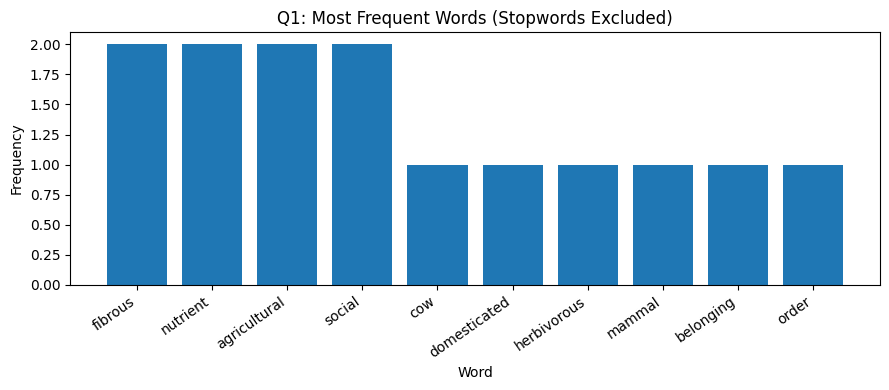

In [2]:
raw_paragraph = """
The cow is a domesticated herbivorous mammal belonging to the order Artiodactyla and the suborder Ruminantia, physiologically adapted to consume fibrous vegetation through a four-compartment stomach and symbiotic microbial fermentation of cellulose.
Its anatomical architecture comprises four weight-bearing limbs, a pair of laterally positioned eyes that provide a broad visual field, a highly sensitive olfactory apparatus, and specialized dentition in which the lower incisors oppose an upper dental pad while the premolars and molars efficiently grind fibrous plant material.
Bovine milk is a biologically complex nutrient matrix containing high-quality proteins, lipids, lactose, calcium, phosphorus, and essential vitamins, serving as a valuable component of human nutrition in fresh, pasteurized, and various processed forms.
Cattle play significant roles in agroecosystems by converting forage into nutrient-dense animal products, contributing to nutrient cycling through manure, supporting certain grassland-management systems, and sustaining agricultural livelihoods through their diverse biological and economic functions.
Beyond their physiological and agricultural significance, cows exhibit social cognition, individual recognition, and affiliative behaviours, enabling them to develop stable social relationships with both conspecifics and humans when provided with appropriate handling, care, and environmental conditions.
""".strip()

# 1. Lowercase and remove punctuation
cleaned_text = re.sub(r"[^a-z0-9\s]", "", raw_paragraph.lower())

# 2. Tokenize words and sentences
sentences = sent_tokenize(raw_paragraph)
words = word_tokenize(cleaned_text)

# 3. Compare split() and word_tokenize()
python_split_tokens = raw_paragraph.split()
nltk_tokens = word_tokenize(raw_paragraph)

print("Cleaned text after processing:\n", cleaned_text)
print("\nSentences:")
for i, sentence in enumerate(sentences, 1):
    print(f"{i}. {sentence}")
print("\nPython split() first 10 tokens:\n", python_split_tokens[:10])
print("\nNLTK word_tokenize() first 10 tokens:\n", nltk_tokens[:10])

# 4. Remove stopwords
stop_words = set(stopwords.words("english"))
filtered_words = [w for w in words if w not in stop_words and w.isalpha()]
print("\nTokens after stopword removal:\n", filtered_words)

# 5. Word frequency distribution
freq = Counter(filtered_words)
print("\nTop word frequencies:")
print(freq.most_common(10))

if freq:
    top_items = freq.most_common(10)
    plt.figure(figsize=(9, 4))
    plt.bar([x[0] for x in top_items], [x[1] for x in top_items])
    plt.title("Q1: Most Frequent Words (Stopwords Excluded)")
    plt.xlabel("Word")
    plt.ylabel("Frequency")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

###  Written Answer & Comparison
- Python `split()`: Simply splits on whitespaces, leaving punctuation attached to words.
- NLTK `word_tokenize()`: Uses linguistic rules to correctly separate words from punctuation marks.

---
## Question 2 — Regex, Stemming & Lemmatization

In [3]:
alpha_words = re.findall(r"\b[a-zA-Z]+\b", raw_paragraph.lower())
alpha_no_stop = [w for w in alpha_words if w not in stop_words]

stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(w) for w in alpha_no_stop]

lemmatizer = WordNetLemmatizer()
lemmatized_words = [lemmatizer.lemmatize(w) for w in alpha_no_stop]

print(f"{'Original':<18} | {'Stemmed':<18} | {'Lemmatized':<18}")
print("-" * 60)
for original, stem, lemma in zip(alpha_no_stop, stemmed_words, lemmatized_words):
    if stem != lemma:
        print(f"{original:<18} | {stem:<18} | {lemma:<18}")

print("\nAll token transformations:")
for original, stem, lemma in zip(alpha_no_stop, stemmed_words, lemmatized_words):
    print(f"{original:>15} -> stem: {stem:<12} lemma: {lemma}")

Original           | Stemmed            | Lemmatized        
------------------------------------------------------------
domesticated       | domest             | domesticated      
herbivorous        | herbivor           | herbivorous       
belonging          | belong             | belonging         
suborder           | subord             | suborder          
physiologically    | physiolog          | physiologically   
adapted            | adapt              | adapted           
consume            | consum             | consume           
fibrous            | fibrou             | fibrous           
vegetation         | veget              | vegetation        
compartment        | compart            | compartment       
symbiotic          | symbiot            | symbiotic         
microbial          | microbi            | microbial         
fermentation       | ferment            | fermentation      
cellulose          | cellulos           | cellulose         
anatomical         | ana

### Q2.5 Written Comparison & Trade-off
- **Differences:** Stemming (Porter) chops off word endings, often leaving non-dictionary roots (e.g., `'domesticated'` becomes `'domest'`, `'herbivorous'` becomes `'herbivor'`). Lemmatization uses a dictionary to return real base words (e.g., `'systems'` becomes `'system'`).
- You should prefer stemming when speed is critical, and we only need rough matching (such as search indexing).
- You should prefer Lemmatization when we need real, readable words for tasks like chatbots or sentiment analysis.

---
## Question 3 — Bag of Words & TF-IDF


In [7]:
texts = [
    "I believe learning responsible use of AI is essential to any Computer Science Engineer.",
    "Growing demand for Data Centres will lead to further degradation of our environment.",
    "People are becoming more aware of AI and its impact on the environment."
]

# 1. Bag of Words
count_vec = CountVectorizer()
bow_matrix = count_vec.fit_transform(texts)
bow_features = count_vec.get_feature_names_out()
print("BoW feature names:\n", bow_features)
print("\nBoW matrix:\n", bow_matrix.toarray())

# 2. TF-IDF
tfidf_vec = TfidfVectorizer()
tfidf_matrix = tfidf_vec.fit_transform(texts)
tfidf_features = tfidf_vec.get_feature_names_out()
print("\nTF-IDF feature names:\n", tfidf_features)
print("\nTF-IDF matrix:\n", np.round(tfidf_matrix.toarray(), 3))

# 3. Top 3 keywords per text
for row_idx, row in enumerate(tfidf_matrix.toarray(), start=1):
    top_indices = row.argsort()[::-1][:3]
    keywords = [(tfidf_features[i], round(float(row[i]), 3)) for i in top_indices if row[i] > 0]
    print(f"Text {row_idx} top keywords: {keywords}")

BoW feature names:
 ['ai' 'and' 'any' 'are' 'aware' 'becoming' 'believe' 'centres' 'computer'
 'data' 'degradation' 'demand' 'engineer' 'environment' 'essential' 'for'
 'further' 'growing' 'impact' 'is' 'its' 'lead' 'learning' 'more' 'of'
 'on' 'our' 'people' 'responsible' 'science' 'the' 'to' 'use' 'will']

BoW matrix:
 [[1 0 1 0 0 0 1 0 1 0 0 0 1 0 1 0 0 0 0 1 0 0 1 0 1 0 0 0 1 1 0 1 1 0]
 [0 0 0 0 0 0 0 1 0 1 1 1 0 1 0 1 1 1 0 0 0 1 0 0 1 0 1 0 0 0 0 1 0 1]
 [1 1 0 1 1 1 0 0 0 0 0 0 0 1 0 0 0 0 1 0 1 0 0 1 1 1 0 1 0 0 1 0 0 0]]

TF-IDF feature names:
 ['ai' 'and' 'any' 'are' 'aware' 'becoming' 'believe' 'centres' 'computer'
 'data' 'degradation' 'demand' 'engineer' 'environment' 'essential' 'for'
 'further' 'growing' 'impact' 'is' 'its' 'lead' 'learning' 'more' 'of'
 'on' 'our' 'people' 'responsible' 'science' 'the' 'to' 'use' 'will']

TF-IDF matrix:
 [[0.224 0.    0.295 0.    0.    0.    0.295 0.    0.295 0.    0.    0.
  0.295 0.    0.295 0.    0.    0.    0.    0.295 0.    0.    

### Q3.3 Interpretation of Top Keywords
- **Text 1:** The top keywords are *use*, *responsible*, and *any*.
- **Text 2:** The top keywords are *will*, *our*, and *centres*.
- **Text 3:** The top keywords are *people*, *the*, and *aware*.

---
## Question 4 — Jaccard & Cosine Similarity


In [8]:
text_1 = """
Black holes form when massive stars collapse under their own gravity.
Gravity near a black hole is so strong that even light cannot escape.
Black hole research includes event horizons, singularities, and gravitational effects.
Advanced observations and accurate measurements are important for understanding black holes.
""".strip()

text_2 = """
Black holes can develop when large stars collapse due to intense gravitational forces.
The gravitational pull of a black hole prevents light from escaping its boundary.
Black hole studies involve cosmic phenomena, spacetime curvature, and accretion disks.
Powerful telescopes and scientific analysis are important for studying these cosmic objects.
""".strip()

# Preprocess and tokenize into sets
tokens_1 = set(re.findall(r"\b[a-z0-9]+\b", text_1.lower()))
tokens_2 = set(re.findall(r"\b[a-z0-9]+\b", text_2.lower()))

def jaccard_similarity(set1, set2):
    union = set1 | set2
    return len(set1 & set2) / len(union) if union else 0.0

jaccard_score = jaccard_similarity(tokens_1, tokens_2)

tfidf_tech = TfidfVectorizer()
tech_matrix = tfidf_tech.fit_transform([text_1, text_2])
cosine_score = float(cosine_similarity(tech_matrix[0:1], tech_matrix[1:2])[0, 0])

print("Unique tokens in text 1:", len(tokens_1))
print("Unique tokens in text 2:", len(tokens_2))
print("Shared tokens:", sorted(tokens_1 & tokens_2))
print(f"Jaccard similarity: {jaccard_score:.4f}")
print(f"TF-IDF cosine similarity: {cosine_score:.4f}")

Unique tokens in text 1: 38
Unique tokens in text 2: 43
Shared tokens: ['a', 'and', 'are', 'black', 'collapse', 'for', 'gravitational', 'hole', 'holes', 'important', 'light', 'stars', 'when']
Jaccard similarity: 0.1912
TF-IDF cosine similarity: 0.3343


### Q4.2c Written Analysis
- **Jaccard Similarity (0.1912):** Measures strict word overlap by dividing shared unique words by total unique words. It is lower because the texts use different words to describe similar ideas.
- **TF-IDF Cosine Similarity (0.3343):** Measures vector angles and word importance. It is higher because it downweights common words and focuses on the alignment of important terms.
- Cosine similarity is better here because it recognizes thematic similarity even when direct word overlap is low.

---
## Question 5 — Sentiment Analysis & Word Cloud


Review 1: Positive
  VADER scores: {'neg': 0.0, 'neu': 0.838, 'pos': 0.162, 'compound': 0.4404}
  Review: The roti maker cooks rotis evenly, is easy to use, and saves time in the kitchen.

Review 2: Negative
  VADER scores: {'neg': 0.329, 'neu': 0.671, 'pos': 0.0, 'compound': -0.659}
  Review: The roti maker heats slowly and stopped working after two days. Very disappointing.

Review 3: Neutral
  VADER scores: {'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound': 0.0}
  Review: The roti maker arrived today. The package contains the appliance and a power cable.



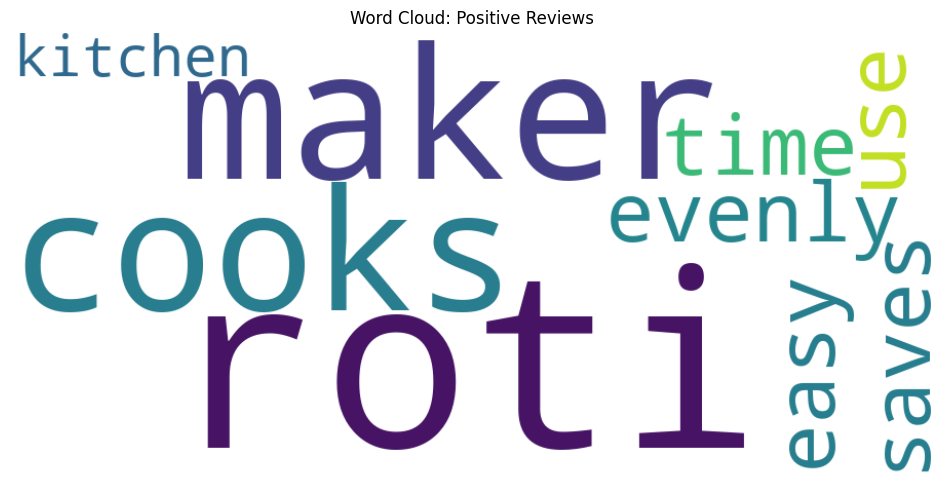

In [9]:
reviews = [
    "The roti maker cooks rotis evenly, is easy to use, and saves time in the kitchen.",
    "The roti maker heats slowly and stopped working after two days. Very disappointing.",
    "The roti maker arrived today. The package contains the appliance and a power cable."
]

sia = SentimentIntensityAnalyzer()
positive_reviews = []
sentiment_results = []

for i, review in enumerate(reviews, start=1):
    scores = sia.polarity_scores(review)
    compound = scores["compound"]
    if compound >= 0.05:
        label = "Positive"
        positive_reviews.append(review)
    elif compound <= -0.05:
        label = "Negative"
    else:
        label = "Neutral"
    sentiment_results.append((i, review, scores, label))
    print(f"Review {i}: {label}")
    print(f"  VADER scores: {scores}")
    print(f"  Review: {review}\n")

# Word cloud from positive reviews only
positive_text = " ".join(positive_reviews)
if positive_text.strip():
    cloud = WordCloud(width=900, height=450, background_color="white",
                      collocations=False).generate(positive_text)
    plt.figure(figsize=(12, 6))
    plt.imshow(cloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud: Positive Reviews")
    plt.show()
else:
    print("No positive reviews were classified, so no word cloud was generated.")

---
## Question 6 — LSTM Next-Word Text Generation


In [11]:
corpus = """
A roti maker helps people prepare fresh rotis quickly at home.
The machine uses heat to cook dough and produce soft flatbreads.
Good quality dough and the right temperature improve the cooking results.
Some roti makers have nonstick plates that make cleaning easier.
A user places the rolled dough inside the machine and closes the lid.
The heating plates cook the roti on both sides within a short time.
Regular cleaning and proper maintenance help the appliance last longer.
Cooking delicious rotis requires practice, patience, and the right technique.
""".strip()

# 1. Tokenization
tokenizer = Tokenizer(oov_token="<OOV>")
tokenizer.fit_on_texts([corpus])
total_words = len(tokenizer.word_index) + 1
print("Vocabulary size:", total_words)

# 2. Create n-gram sequences
input_sequences = []
for line in corpus.split("\n"):
    line = line.strip()
    if not line:
        continue
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(2, len(token_list) + 1):
        input_sequences.append(token_list[:i])

if not input_sequences:
    raise ValueError("The corpus did not produce any training sequences.")

max_sequence_len = max(len(seq) for seq in input_sequences)
padded_sequences = pad_sequences(input_sequences, maxlen=max_sequence_len, padding="pre")
X = padded_sequences[:, :-1]
y = to_categorical(padded_sequences[:, -1], num_classes=total_words)

model = Sequential([
    Embedding(input_dim=total_words, output_dim=32, input_length=max_sequence_len - 1),
    LSTM(64),
    Dense(total_words, activation="softmax")
])
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model.summary()

# A modest epoch count keeps the lab exercise manageable.
history = model.fit(X, y, epochs=100, verbose=0)
print("Training complete.")
print(f"Final training accuracy: {history.history['accuracy'][-1]:.3f}")

Vocabulary size: 65


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Training complete.
Final training accuracy: 0.593


In [13]:
def generate_text(seed_text, next_words, model, max_sequence_len):
    generated = seed_text.strip()
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([generated])[0]
        token_list = pad_sequences(
            [token_list], maxlen=max_sequence_len - 1, padding="pre"
        )
        predictions = model.predict(token_list, verbose=0)[0]

        # Choose the highest-probability non-padding token.
        predicted_index = int(np.argmax(predictions))
        if predicted_index == 0:
            break
        output_word = tokenizer.index_word.get(predicted_index)
        if not output_word or output_word == "<OOV>":
            break
        generated += " " + output_word
    return generated
print("Generated text:")
print(generate_text("a roti maker", 20, model, max_sequence_len))
print()
print(generate_text("the heating plates", 20, model, max_sequence_len))

Generated text:
a roti maker roti people prepare fresh rotis quickly at home time time time time time time time time time time time time

the heating plates cook cook and on both sides within a time time time time time time time time time time time results
